# Análisis de Sentimiento con RNN (LSTM)

**Dataset:** IMDB Reviews (50.000 reseñas de películas en inglés, positiva/negativa)
## Objetivo del proyecto

Entrenar una red neuronal capaz de leer una reseña de película (texto) y decidir si es
**positiva** o **negativa**.

### ¿Qué es una RNN, y por qué LSTM?

Una red neuronal normal (como la CNN del trabajo anterior) recibe toda la entrada de una vez.
Pero el texto es secuencial: el orden de las palabras importa, y para entender una oración
hay que "recordar" lo que se leyó antes. Una **RNN (Red Neuronal Recurrente)** está diseñada
para eso: procesa la secuencia palabra por palabra, y en cada paso mantiene una "memoria" de lo
que ha visto hasta el momento.

El problema de una RNN simple es que esa memoria se va "olvidando" rápido en textos largos
(se le conoce como el problema del *vanishing gradient*). Por eso usamos LSTM (*Long
Short-Term Memory*), una variante de RNN con una memoria más sofisticada que decide
explícitamente qué recordar y qué olvidar, y que funciona mucho mejor con textos de varias
oraciones, como una reseña de película.

### Estructura de este notebook

1. Instalación e importación de librerías
2. Descripción y descarga del dataset
3. Análisis exploratorio de los datos
4. Limpieza y preprocesamiento (texto → números)
5. División en entrenamiento / validación / prueba
6. Construcción de la red (Embedding + LSTM)
7. Entrenamiento
8. Gráficas del entrenamiento
9. Evaluación (métricas y matriz de confusión)
10. Predicciones con reseñas reales
11. Guardado del modelo
12. Conclusiones


In [ ]:
import os
import re
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.metrics import classification_report, confusion_matrix

print("TensorFlow version:", tf.__version__)
print("GPU disponible:", tf.config.list_physical_devices('GPU'))

SEED = 42
tf.random.set_seed(SEED)
np.random.seed(SEED)


TensorFlow version: 2.21.0
GPU disponible: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## Descripción y descarga del dataset

### 2.1 ¿Qué es "IMDB Reviews"?

Es un dataset público y muy usado en cursos de NLP (procesamiento de lenguaje natural):
50.000 reseñas de películas escritas por usuarios reales de IMDB, ya etiquetadas como
pos (positiva) o neg (negativa). Viene dividido en 25.000 para entrenamiento y 25.000
para prueba, balanceado 50/50 entre las dos clases.



In [ ]:
import tarfile

URL_DATASET = "https://ai.stanford.edu/~amaas/data/sentiment/aclImdb_v1.tar.gz"

# Paso 1: descargar el archivo comprimido (sin extraer todavía)
ruta_descarga = keras.utils.get_file(
    fname="aclImdb_v1.tar.gz",
    origin=URL_DATASET,
    cache_dir=".",
    cache_subdir="",
)
print("Archivo descargado en:", ruta_descarga)

# Paso 2: extraerlo nosotros mismos, de forma explícita (más confiable)
if not os.path.exists("aclImdb"):
    print("Extrayendo, puede tardar 1-2 minutos...")
    with tarfile.open(ruta_descarga) as tar:
        tar.extractall()
    print("Extracción completa.")
else:
    print("La carpeta aclImdb ya existe, no hace falta extraer de nuevo.")

BASE_DIR = "aclImdb"
TRAIN_DIR = os.path.join(BASE_DIR, "train")
TEST_DIR = os.path.join(BASE_DIR, "test")

# Quitar la subcarpeta "unsup" (reseñas sin etiqueta, no la usamos)
import shutil
carpeta_unsup = os.path.join(TRAIN_DIR, "unsup")
if os.path.exists(carpeta_unsup):
    shutil.rmtree(carpeta_unsup)

print(os.listdir(TRAIN_DIR))
print(os.listdir(TEST_DIR))


Archivo descargado en: ./aclImdb_v1.tar.gz
La carpeta aclImdb ya existe, no hace falta extraer de nuevo.
['unsupBow.feat', 'urls_pos.txt', 'urls_neg.txt', 'labeledBow.feat', 'pos', 'neg', 'urls_unsup.txt']
['urls_pos.txt', 'urls_neg.txt', 'labeledBow.feat', 'pos', 'neg']


In [ ]:
# Conteo de reseñas por clase
def contar_por_clase(directorio):
    conteo = {}
    for clase in ["pos", "neg"]:
        ruta_clase = os.path.join(directorio, clase)
        conteo[clase] = len(os.listdir(ruta_clase))
    return conteo

conteo_train = contar_por_clase(TRAIN_DIR)
conteo_test = contar_por_clase(TEST_DIR)

df_conteo = pd.DataFrame({"train": conteo_train, "test": conteo_test})
df_conteo["total"] = df_conteo["train"] + df_conteo["test"]
df_conteo


,train,test,total
pos,12500,12500,25000
neg,12500,12500,25000


La tabla muestra cuántas reseñas positivas y negativas hay. Este
dataset viene perfectamente balanceado (12.500 y 12.500 en train, 12.500 y 12.500 en test),
así que no tenemos el problema de clases desbalanceadas que sí tocamos revisar en el trabajo
de la CNN

# Análisis exploratorio de los datos


In [ ]:
# Ver un par de reseñas de ejemplo, una de cada clase
def leer_ejemplo(clase):
    carpeta = os.path.join(TRAIN_DIR, clase)
    archivo = os.listdir(carpeta)[0]
    with open(os.path.join(carpeta, archivo), encoding="utf-8") as f:
        return f.read()

print("=== Ejemplo POSITIVO ===")
print(leer_ejemplo("pos")[:500], "...\n")

print("=== Ejemplo NEGATIVO ===")
print(leer_ejemplo("neg")[:500], "...")


=== Ejemplo POSITIVO ===
I love this movie. It's wacky, funny, violent, surreal, played out in a madman's head, and definitely not your usual comedy. <br /><br />If you don't find the film amusing then I guess it's just not for your tastes, so this is a tough one to write a review for.<br /><br />For reference, some other comedies I love are The Big Lebowski, The Princess Bride, and Zoolander (that one only got me the second time around). There are others, but my taste is definitely for the unusual, and I am willing to  ...

=== Ejemplo NEGATIVO ===
On Broadway, A Chorus Line was pure magic. From the second the show opened with a spectacular burst of energy to the truly grand finale, a joyous curtain call of all those chorus members who we grew to love during the course of the show, we were totally engaged - captivated by the intensely personal stories, some funny, some clever, some stirring, of this chorus line. The movie is another matter entirely. The focus is now on the director - 

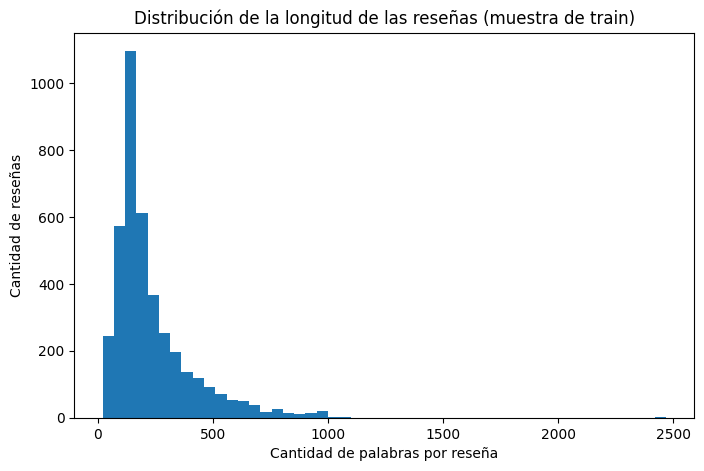

Promedio de palabras por reseña: 233
Mediana: 173
Máximo: 2470
Percentil 95: 602


In [ ]:
# Distribución de la longitud de las reseñas (en cantidad de palabras)
def longitudes(directorio, n_muestra=2000):
    largos = []
    for clase in ["pos", "neg"]:
        carpeta = os.path.join(directorio, clase)
        archivos = os.listdir(carpeta)[:n_muestra]
        for archivo in archivos:
            with open(os.path.join(carpeta, archivo), encoding="utf-8") as f:
                texto = f.read()
            largos.append(len(texto.split()))
    return largos

largos_train = longitudes(TRAIN_DIR)

plt.figure(figsize=(8, 5))
plt.hist(largos_train, bins=50)
plt.xlabel("Cantidad de palabras por reseña")
plt.ylabel("Cantidad de reseñas")
plt.title("Distribución de la longitud de las reseñas (muestra de train)")
plt.show()

print(f"Promedio de palabras por reseña: {np.mean(largos_train):.0f}")
print(f"Mediana: {np.median(largos_train):.0f}")
print(f"Máximo: {np.max(largos_train)}")
print(f"Percentil 95: {np.percentile(largos_train, 95):.0f}")


Esta gráfica nos dice cuántas palabras tiene una reseña típica.
Esto es importante para el siguiente paso, porque vamos a tener que decidir una longitud fija
de "corte" (si una reseña es más larga, la recortamos; si es más corta, la rellenamos con
ceros)  y conviene elegir ese número mirando dónde cae la mayoría de las reseñas, no un
número al azar.

### RESULTADO

Las clases están perfectamente balanceadas: 12.500 positivas y 12.500 negativas, tanto en train como en test. Eso es ideal porque el modelo no tiene ningún motivo para "preferir" una clase sobre la otra solo por cantidad de ejemplos.

En los ejemplos de reseña sí noto una diferencia de tono: la positiva usa palabras como "love", "funny" y "amusing", mientras que la negativa describe una decepción (compara la película con la obra de teatro original y dice que "es otro asunto completamente distinto"). Tiene sentido que el modelo pueda aprender a reconocer ese tipo de vocabulario.

Sobre la longitud: el promedio es de 233 palabras y la mediana de 173, pero el máximo llega a 2.470 palabras, y el percentil 95 está en 602. Eso quiere decir que hay un grupo de reseñas bastante largas (muy por encima del promedio). Como nuestro modelo corta todo a 250 palabras, esas reseñas largas van a perder buena parte de su contenido (todo lo que esté después de la palabra 250), lo cual sí podría ser un caso difícil para el modelo.


## Limpieza y preprocesamiento


Las reseñas vienen con **etiquetas HTML** sueltas (por ejemplo `<br />` de saltos de línea) que
no aportan nada al significado del texto, así que las quitamos. También pasamos todo a
minúsculas, para que "Great" y "great" se traten como la misma palabra.

### ¿Cómo convertimos texto en números?

Una red neuronal no entiende palabras, entiende números. Usamos una capa de Keras llamada
**`TextVectorization`**, que hace dos cosas:

1. Construye un **vocabulario**: la lista de las N palabras más frecuentes del dataset de
   entrenamiento (en nuestro caso, las 10.000 más comunes). Cada palabra del vocabulario
   recibe un número único (su "índice").
2. **Convierte cada reseña** en una secuencia de esos números, en el mismo orden en que
   aparecen las palabras, y recorta o rellena con ceros para que todas las secuencias queden
   del mismo largo (usamos 250 palabras, según lo que vimos en la exploración).

Esta capa la "entrenamos" (adapt) solo con el texto de entrenamiento nunca con
validación ni test, para no hacer trampa mostrándole al modelo vocabulario que en teoría no
debería conocer todavía

In [ ]:
def limpiar_texto(texto):
    texto = tf.strings.lower(texto)
    texto = tf.strings.regex_replace(texto, "<br />", " ")
    texto = tf.strings.regex_replace(texto, "[^a-záéíóúñü' ]", " ")
    return texto

VOCAB_SIZE = 10000
LONGITUD_SECUENCIA = 250

vectorizador = layers.TextVectorization(
    standardize=limpiar_texto,
    max_tokens=VOCAB_SIZE,
    output_mode="int",
    output_sequence_length=LONGITUD_SECUENCIA,
)


##  División en entrenamiento, validación y prueba

- **Entrenamiento:** de donde la red aprende (y de donde `TextVectorization` aprende su
  vocabulario).
- **Validación:** vigilamos el desempeño durante el entrenamiento, sin usarla para ajustar
  pesos.
- **Prueba:** el examen final, con reseñas que el modelo nunca vio.


In [ ]:
BATCH_SIZE = 32

train_ds = keras.utils.text_dataset_from_directory(
    TRAIN_DIR,
    batch_size=BATCH_SIZE,
    validation_split=0.2,
    subset="training",
    seed=SEED,
)

val_ds = keras.utils.text_dataset_from_directory(
    TRAIN_DIR,
    batch_size=BATCH_SIZE,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
)

test_ds = keras.utils.text_dataset_from_directory(
    TEST_DIR,
    batch_size=BATCH_SIZE,
    shuffle=False,  # no mezclar el test, para poder comparar predicciones vs etiquetas reales en orden
)

CLASS_NAMES = train_ds.class_names
print("Clases (en el orden que usará el modelo):", CLASS_NAMES)


Found 25000 files belonging to 2 classes.
Using 20000 files for training.
Found 25000 files belonging to 2 classes.
Using 5000 files for validation.
Found 25000 files belonging to 2 classes.
Clases (en el orden que usará el modelo): ['neg', 'pos']


In [ ]:
# Adaptar el vectorizador SOLO con el texto de entrenamiento
texto_entrenamiento = train_ds.map(lambda x, y: x)
vectorizador.adapt(texto_entrenamiento)

print("Tamaño real del vocabulario:", len(vectorizador.get_vocabulary()))
print("Primeras 10 palabras del vocabulario:", vectorizador.get_vocabulary()[:10])


Tamaño real del vocabulario: 10000
Primeras 10 palabras del vocabulario: ['', '[UNK]', np.str_('the'), np.str_('and'), np.str_('a'), np.str_('of'), np.str_('to'), np.str_('is'), np.str_('in'), np.str_('it')]


In [ ]:
# Aplicar el vectorizador a los 3 conjuntos, y optimizar la lectura
def vectorizar(texto, etiqueta):
    return vectorizador(texto), etiqueta

AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.map(vectorizar).cache().prefetch(AUTOTUNE)
val_ds = val_ds.map(vectorizar).cache().prefetch(AUTOTUNE)
test_ds = test_ds.map(vectorizar).cache().prefetch(AUTOTUNE)


## Construcción de la red (Embedding + LSTM)

- **Capa Embeddind:** convierte cada número de palabra en un **vector de significado** (en
  nuestro caso, de 64 dimensiones). La idea es que palabras con significado parecido (por
  ejemplo "great" y "excellent") terminen con vectores parecidos. Esta capa la aprende la red
  sola durante el entrenamiento, no se la damos nosotros.
- **Capa Bidirectional(LSTM):** el corazón de la red. Una LSTM normal lee la reseña de
  izquierda a derecha; una LSTM **bidireccional** la lee también de derecha a izquierda y
  combina ambas lecturas, lo que suele capturar mejor el contexto de una oración.
- **Dropout:** igual que en la CNN, apaga neuronas al azar durante el entrenamiento para
  evitar que la red memorice en vez de aprender patrones generales.
- **Capa de salida con sigmoid:** como es clasificación binaria (positiva/negativa), basta
  con una sola neurona de salida que da un número entre 0 y 1 entre más cerca de 1, más
  "positiva" cree la red que es la reseña.

In [ ]:
modelo = keras.Sequential([
    keras.Input(shape=(LONGITUD_SECUENCIA,)),
    layers.Embedding(input_dim=VOCAB_SIZE, output_dim=64, mask_zero=True),
    layers.Bidirectional(layers.LSTM(64, return_sequences=True)),
    layers.Bidirectional(layers.LSTM(32)),
    layers.Dropout(0.5),
    layers.Dense(32, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(1, activation="sigmoid"),
], name="lstm_imdb_sentimiento")

modelo.summary()


Model: "lstm_imdb_sentimiento"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 250, 64)        │       640,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_2 (Bidirectional) │ (None, 250, 128)       │        66,048 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_3 (Bidirectional) │ (None, 64)             │        41,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 749,377 (2.86 MB)

 Trainable params: 749,377 (2.86 MB)

 Non-trainable params: 0 (0.00 B)

## Entrenamiento

### Decisiones:

- **Loss `binary_crossentropy`:** la función de error estándar para clasificación binaria
  (dos clases) cuando la salida es una probabilidad (gracias a la `sigmoid` del paso anterior).
- **Optimizador `adam`:** igual que en la CNN.
- **`EarlyStopping`** y **`ModelCheckpoint`:** iguales que en la CNN — detener el
  entrenamiento si la validación deja de mejorar, y quedarnos con los mejores pesos.

In [ ]:
modelo.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"],
)

callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True),
    keras.callbacks.ModelCheckpoint("mejor_modelo.keras", monitor="val_accuracy", save_best_only=True),
]

EPOCHS = 15

historia = modelo.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks,
)


Epoch 1/15
625/625 ━━━━━━━━━━━━━━━━━━━━ 32s 46ms/step - accuracy: 0.7610 - loss: 0.4899 - val_accuracy: 0.7796 - val_loss: 0.4366
Epoch 2/15
625/625 ━━━━━━━━━━━━━━━━━━━━ 26s 41ms/step - accuracy: 0.8874 - loss: 0.2909 - val_accuracy: 0.8586 - val_loss: 0.3168
Epoch 3/15
625/625 ━━━━━━━━━━━━━━━━━━━━ 26s 41ms/step - accuracy: 0.9294 - loss: 0.2004 - val_accuracy: 0.8636 - val_loss: 0.3407
Epoch 4/15
625/625 ━━━━━━━━━━━━━━━━━━━━ 25s 41ms/step - accuracy: 0.9481 - loss: 0.1485 - val_accuracy: 0.8526 - val_loss: 0.4214
Epoch 5/15
625/625 ━━━━━━━━━━━━━━━━━━━━ 26s 41ms/step - accuracy: 0.9598 - loss: 0.1100 - val_accuracy: 0.8250 - val_loss: 0.6207


## Gráficas del entrenamiento


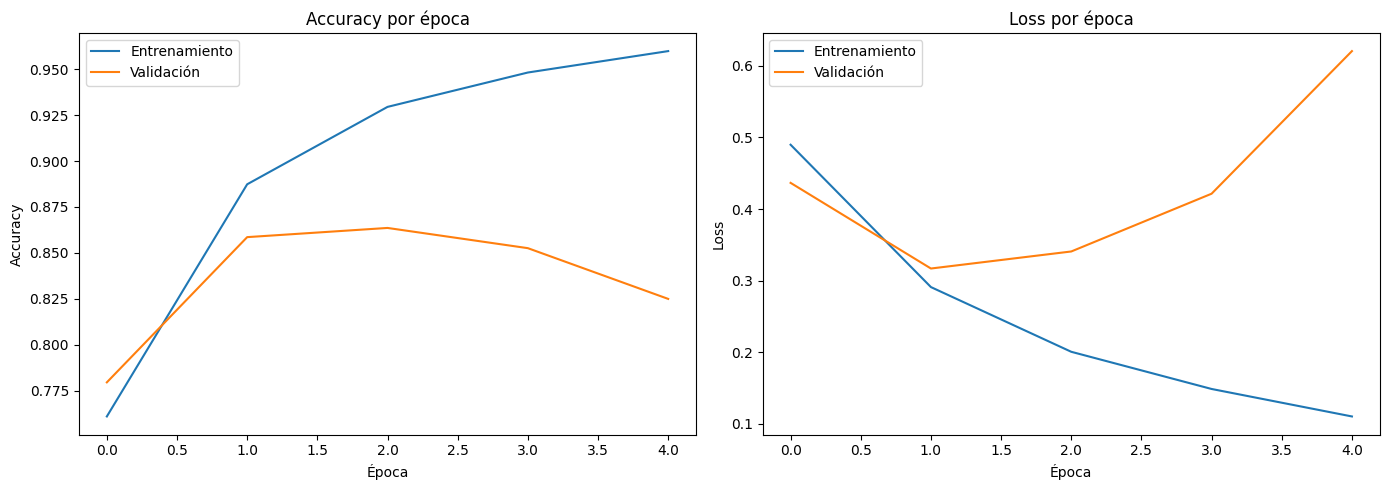

In [ ]:
hist = historia.history

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(hist["accuracy"], label="Entrenamiento")
axes[0].plot(hist["val_accuracy"], label="Validación")
axes[0].set_title("Accuracy por época")
axes[0].set_xlabel("Época")
axes[0].set_ylabel("Accuracy")
axes[0].legend()

axes[1].plot(hist["loss"], label="Entrenamiento")
axes[1].plot(hist["val_loss"], label="Validación")
axes[1].set_title("Loss por época")
axes[1].set_xlabel("Época")
axes[1].set_ylabel("Loss")
axes[1].legend()

plt.tight_layout()
plt.show()


### RESULTADO

Acá sí se ve un caso bastante claro de overfitting. La curva de entrenamiento (azul) sube todo el tiempo, de 76% a casi 96% de accuracy, y su loss baja sin parar hasta 0.11. Pero la curva de validación (naranja) solo mejora hasta la época 2 (86.4% de accuracy, loss de 0.317) y después empieza a empeorar: para la época 5 ya había bajado a 82.5% de accuracy y su loss había subido hasta 0.62.

Es decir, después de la época 2 el modelo dejó de aprender cosas que generalizan y empezó a "memorizar" las reseñas de entrenamiento. Por eso el entrenamiento se detuvo solo en la época 5: el `EarlyStopping` esperó 3 épocas sin mejora en el val_loss (épocas 3, 4 y 5) y paró ahí, quedándose con los pesos de la época 2 (`restore_best_weights=True`), que fue el mejor punto antes de que empezara a empeorar.


## Evaluación con métricas apropiadas

Evaluamos con el conjunto de **prueba** (reseñas que el modelo nunca vio).

- **Accuracy:** % total de aciertos.
- **Precision, Recall, F1-score:** igual que en los trabajos anteriores.
- **Matriz de confusión:** cuántas reseñas positivas/negativas se clasificaron bien o mal.

Como la salida del modelo es una probabilidad entre 0 y 1 (por la sigmoid), convertimos a
clase usando 0.5 como umbral: si es mayor a 0.5, la llamamos "positiva"; si no, "negativa"

In [ ]:
test_loss, test_accuracy = modelo.evaluate(test_ds)
print(f"Accuracy en test: {test_accuracy:.4f}")
print(f"Loss en test: {test_loss:.4f}")


782/782 ━━━━━━━━━━━━━━━━━━━━ 16s 20ms/step - accuracy: 0.8480 - loss: 0.3403
Accuracy en test: 0.8480
Loss en test: 0.3403


In [ ]:
y_true = np.concatenate([y.numpy() for _, y in test_ds])
y_pred_probs = modelo.predict(test_ds).ravel()
y_pred = (y_pred_probs > 0.5).astype(int)

print(classification_report(y_true, y_pred, target_names=CLASS_NAMES))


782/782 ━━━━━━━━━━━━━━━━━━━━ 12s 15ms/step
              precision    recall  f1-score   support

         neg       0.81      0.91      0.86     12500
         pos       0.89      0.79      0.84     12500

    accuracy                           0.85     25000
   macro avg       0.85      0.85      0.85     25000
weighted avg       0.85      0.85      0.85     25000



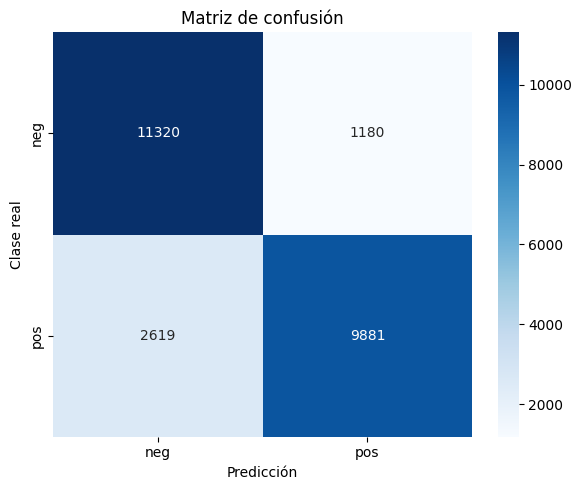

In [ ]:
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
plt.xlabel("Predicción")
plt.ylabel("Clase real")
plt.title("Matriz de confusión")
plt.tight_layout()
plt.show()


### RESULTADO

El accuracy final en el conjunto de prueba fue **84.8%** (test loss 0.34), un poco más bajo que el mejor punto de validación (86.4% en la época 2), lo cual es esperable porque el modelo final mezcla un poco de ese overfitting que vimos antes.

Mirando el reporte y la matriz de confusión, el modelo no se equivoca parejo entre las dos clases:
- Es muy bueno detectando reseñas **negativas**: recall de 0.91 (de cada 100 negativas reales, detecta 91).
- Le cuesta más detectar reseñas **positivas**: recall de solo 0.79. De hecho, en la matriz de confusión se ve que **2.619 reseñas positivas fueron clasificadas como negativas** — es, por mucho, el error más grande del modelo (contra solo 1.180 negativas clasificadas como positivas).

Esto sugiere que el modelo tiene una especie de "sesgo" hacia predecir negativo: cuando una reseña positiva tiene algo de lenguaje crítico o mixto (como el ejemplo que vimos en la exploración, que elogia la obra pero critica la película), el modelo tiende a inclinarse por "negativa".


## Predicciones con reseñas reales

Se muestran 12 reseñas del conjunto de prueba junto con la clase predicha, la clase real, y el
nivel de confianza de la predicción.

In [ ]:
# Volvemos a leer el test set sin vectorizar, solo para poder mostrar el texto original
test_ds_texto = keras.utils.text_dataset_from_directory(
    TEST_DIR, batch_size=BATCH_SIZE, shuffle=False,
)

N_EJEMPLOS = 12
mostrados = 0
indice_global = 0

for textos, etiquetas in test_ds_texto:
    for i in range(len(textos)):
        if mostrados >= N_EJEMPLOS:
            break
        texto = textos[i].numpy().decode("utf-8")
        real = CLASS_NAMES[etiquetas[i].numpy()]
        prob = y_pred_probs[indice_global]
        pred = CLASS_NAMES[int(prob > 0.5)]
        confianza = (prob if prob > 0.5 else 1 - prob) * 100

        color = "✅" if pred == real else "❌"
        print(f"{color} Real: {real:8s} | Predicción: {pred:8s} ({confianza:.1f}% confianza)")
        print(f"   Reseña: {texto[:180]}...")
        print()

        mostrados += 1
        indice_global += 1
    if mostrados >= N_EJEMPLOS:
        break


Found 25000 files belonging to 2 classes.
✅ Real: neg      | Predicción: neg      (78.5% confianza)
   Reseña: Once again Mr. Costner has dragged out a movie for far longer than necessary. Aside from the terrific sea rescue sequences, of which there are very few I just did not care about an...

✅ Real: neg      | Predicción: neg      (97.9% confianza)
   Reseña: This is an example of why the majority of action films are the same. Generic and boring, there's really nothing worth watching here. A complete waste of the then barely-tapped tale...

✅ Real: neg      | Predicción: neg      (95.8% confianza)
   Reseña: First of all I hate those moronic rappers, who could'nt act if they had a gun pressed against their foreheads. All they do is curse and shoot each other and acting like cliché'e ve...

✅ Real: neg      | Predicción: neg      (88.5% confianza)
   Reseña: Not even the Beatles could write songs everyone liked, and although Walter Hill is no mop-top he's second to none when it comes

In [ ]:
# Armamos un modelo "completo" que incluye el vectorizador como primera capa
modelo_completo = keras.Sequential([
    keras.Input(shape=(1,), dtype=tf.string),
    vectorizador,
    modelo,
])

modelo_completo.save("modelo_sentimiento_imdb.keras")

with open("class_names.json", "w") as f:
    json.dump(CLASS_NAMES, f)

print("Modelo guardado como modelo_sentimiento_imdb.keras")
print("Clases guardadas como class_names.json:", CLASS_NAMES)

# Prueba rápida: el modelo completo debe aceptar texto crudo directamente
prueba = tf.constant(["This movie was absolutely wonderful, I loved every minute of it!"])
print("Predicción de prueba (texto crudo):", modelo_completo.predict(prueba))

from google.colab import files
files.download("modelo_sentimiento_imdb.keras")
files.download("class_names.json")


Modelo guardado como modelo_sentimiento_imdb.keras
Clases guardadas como class_names.json: ['neg', 'pos']
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 430ms/step
Predicción de prueba (texto crudo): [[0.9132613]]


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Conclusiones y limitaciones


En general el modelo quedó bien: 84.8% de accuracy en una tarea de dos clases, muy por encima del 50% que daría adivinar al azar. Aprendió a distinguir bastante bien el lenguaje de una reseña negativa, aunque le cuesta un poco más detectar las positivas, sobre todo las que mezclan elogios con alguna crítica.

**Limitaciones que encontré:**
- El modelo mostró overfitting claro desde la época 2: la red es bastante grande (dos capas LSTM bidireccionales) para la cantidad de datos, y memoriza rápido.
- El vocabulario se limita a las 10.000 palabras más frecuentes, y las reseñas se cortan a 250 palabras. Como vimos en la exploración, hay reseñas de hasta 2.470 palabras, así que una parte del contenido de las reseñas más largas se pierde.
- El dataset está solo en inglés, así que el modelo no sirve directamente para reseñas en español.
- Hay una asimetría en los errores: el modelo detecta mejor lo negativo que lo positivo.


